In [1]:
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')

import os
import sys
sys.stderr = open(os.devnull, 'w')

In [2]:
%matplotlib inline

import numpy as np

from triqs.plot.mpl_interface import plt

In [3]:
plt.style.use('notebook.mplstyle')

# Extracting Superconducting Length Scales from Eliashberg Theory

In a previous tutorial ([here](https://triqs.github.io/tprf/unstable/user_guide/Linearized%20Eliashberg%20equation%20on%20the%20attractive%20Hubbard%20model.html)) we studied the linearized Eliashberg equation on the attractive Hubbard model.
There we showed how we can extract the critical temperature from linearized Eliashberg equation as the temperature where the maximal eigenvalue crosses unity.

In the following we will expand on those concepts and show how one can extract superconducting length scales, such as the coherence length $\xi$ or the London penetration depth $\lambda_L$, from the Eliashberg theory by applying a finite momentum pairing (FMP) constraint to the Cooper pairs.
The original work implementing this method for dynamical mean field theory is [N. Witt et al., npj. Quantum Materials 9, 100 (2024)](https://doi.org/10.1038/s41535-024-00706-7).

## Hubbard model

We will use the same Hamiltonian as discussed in the previous tutorial

$$
H=-t \sum_{\langle j, l\rangle \sigma}\left(c_{j \sigma}^{\dagger} c_{l \sigma}+c_{l \sigma}^{\dagger} c_{j \sigma}\right)+U \sum_{j}\left(n_{j \uparrow}-\frac{1}{2}\right)\left(n_{j \downarrow}-\frac{1}{2}\right)-\mu \sum_{j}\left(n_{j \uparrow}+n_{j \downarrow}\right)\,.
$$

And as before, we will record its parameters using the `ParameterCollection` class of `triqs_tprf.ParameterCollection` module.
Note that we now immediately set a negative $U$ to promote s-wave superconductivity, and a non-zero chemical potential. We furthermore define a center-of-mass momentum $Q$ for the Cooper pairs, but set it to zero for now.

In [4]:
from triqs_tprf.ParameterCollection import ParameterCollection

hubbard = ParameterCollection(   # -- Model Parameter
                                 norb=1, # Number of orbitals.
                                 t=1.0, # Hopping to nearest neighbor
                                 U=-2.0, # Strength of the on-site interaction
                                 mu=-1.0, # Chemical potential determining the filling.
                                 T=1000, # Temperature.
                                 spin=False, # Treat indices only for orbital character.
                                 Q=np.array([0.0,0.0,0.0]), # Cooper pair center-of-mass momentum
                
                                 # -- Technical parameter
                                 nk=96, # Number of points in one dimension considered in the Brillouin zone.
                                 nw=200, # Number of Matsubara points in positive dimension.
                                        )
hubbard

Q = [0. 0. 0.]
T = 1000
U = -2.0
mu = -1.0
nk = 96
norb = 1
nw = 200
spin = False
t = 1.0

Unlike before, we will consider a single-orbital one-dimensional chain of atoms, in order to make the calculations faster.
Our electron dispersion is therefore

$$
\varepsilon(k) = - 2t \cos(k)\,,
$$

which we will construct as follows

In [5]:
from triqs.gfs import Gf
from triqs.mesh import MeshBrZone
from triqs.lattice.lattice_tools import BrillouinZone, BravaisLattice

def dispersion(k, t):
    return -2.0 * t * np.cos(k[0])

bl = BravaisLattice(units=[(1,0,0)], orbital_positions=[(0,0,0)])
bz = BrillouinZone(bl)
kmesh = MeshBrZone(bz, [hubbard.nk, 1, 1])

e_k = Gf(mesh=kmesh, target_shape=[hubbard.norb]*2)
for k in kmesh:
    e_k[k] = dispersion(k.value, hubbard.t)

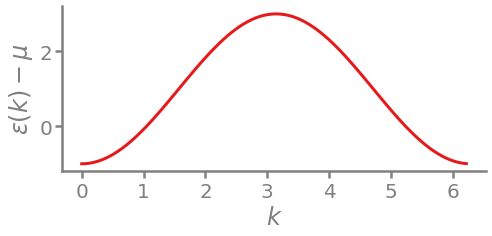

In [6]:
plt.figure(figsize=(3.25*2, 3))

karr = [k.value[0] for k in kmesh]
plt.plot(karr, e_k.data[:,0,0].real - hubbard.mu)

plt.tight_layout()
plt.xlabel(r"$k$")
plt.ylabel(r"$\varepsilon(k) - \mu$")

plt.show()

## Finite momentum pairing

In order to enforce a finite center-of-mass momentum $Q$ to the Cooper pairs, we enforce the superconducting order parameter to have the following form

$$
\Psi_Q(r) = |\Psi_Q| e^{iQr}\,.
$$

Fourier transforming this expression to momentum space, one can show that the additional factor of $Q$ in the exponential can be treated by effectively shifting the momentum index of the hole dispersion by $Q$. 
Defining bare Hamiltonian in the Nambu-Gor'kov basis as $\mathbf{H}^{(0)}_{Q}(k)$, this boils down to

$$
\mathbf{H}^{(0)}_{Q}(k) =
\begin{pmatrix}
    \varepsilon(k) & 0 \\
    0 & \bar{\varepsilon}(-k + Q)
\end{pmatrix}\,,
$$

where the dispersion of the holes is simply given by $\bar{\varepsilon}(k) = -\varepsilon(k)$.
Note that at $Q=0$ we recover the usual Nambu-Gor'kov Hamiltonian. 
The linearized Eliashberg equation now becomes (neglecting normal state renormalization)

$$
\lambda(T,Q) \Delta_{Q}(k,i\omega_n)=  -\frac{1}{2 N_{\mathbf{k}}\beta}\sum_{k',n'}
    \Gamma(k-k',i\omega_n-i\omega_{n'})
    G^{(0)}(k',i\omega_{n'}) \bar{G}^{(0)}(-k' + Q, -i\omega_{n'})
    \Delta_{Q}(k',i\omega_{n'})\,,
$$

where the leading eigenvalue $\lambda$ is now dependent on both the temperature $T$ and the Cooper pair momentum $Q$. Note that the two bare Green's functions $G^{(0)}$ now have different momentum arguments. 

From the order parameter defined above we understand that, as we increase the Cooper pair momentum $Q$, the order parameter acquires a non-zero phase. 
At some critical $Q_c$, the kinetic energy cost of those phase modulations becomes larger than the energy gain from Cooper pairing, such that the superconducting order breaks down.
The length scale of this breakdown is the coherence length, which we define as $\xi = 1/Q_c$ (see also [N. Witt et al., npj. Quantum Materials 9, 100 (2024)](https://doi.org/10.1038/s41535-024-00706-7)).

In practice we can obtain $Q_c$ in the same way as we obtain the critical temperature.
We sweep $Q$ at a fixed temperature $T$, and find the critical $Q_c$ at which the leading eigenvalue $\lambda$ of the linearized gap equation is unity. The coherence length is then given by

$$
\xi(T) = \frac{1}{Q_c(T)}\,.
$$

## Implementation in TPRF

To start, we construct the dispersion similar to before, but we define a hole dispersion which has its momentum argument shifted by $Q$. Note that we need to give TPRF the Green's function without the inverted arguments (i.e., $\bar{G}^{(0)}(k+Q,i\omega_n)$, and not $\bar{G}^{(0)}(-k+Q,-i\omega_n)$). We therefore define the hole dispersion as $\varepsilon(k + Q)$.

In [67]:
hubbard.Q = np.array([0.5, 0.0, 0.0])

e_k = Gf(mesh=kmesh, target_shape=[hubbard.norb]*2)
ebar_k = Gf(mesh=kmesh, target_shape=[hubbard.norb]*2)
for k in kmesh:
    e_k[k] = dispersion(k.value, hubbard.t)
    ebar_k[k] = dispersion(k.value + hubbard.Q, hubbard.t)

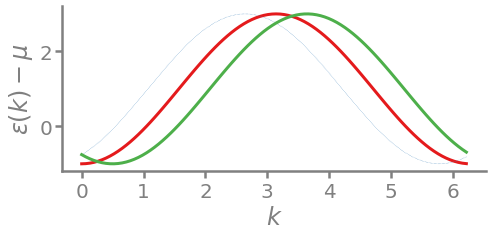

In [71]:
plt.figure(figsize=(3.25*2, 3))

karr = [k.value[0] for k in kmesh]
plt.plot(karr, e_k.data[:,0,0].real - hubbard.mu)
plt.plot(karr, ebar_k.data[:,0,0].real - hubbard.mu, linewidth=0.5, linestyle=':')

etemp_k = ebar_k.copy()
for k in kmesh:
    etemp_k[k] = ebar_k(-k)

plt.plot(karr, etemp_k.data[:,0,0].real - hubbard.mu)
    
plt.tight_layout()
plt.xlabel(r"$k$")
plt.ylabel(r"$\varepsilon(k) - \mu$")

plt.show()

Then we construct the bare Green's functions

In [64]:
from triqs_tprf.lattice import lattice_dyson_g0_wk
from triqs.mesh import MeshImFreq
from triqs_tprf.utilities import temperature_to_beta

beta = temperature_to_beta(hubbard.T)
wmesh = MeshImFreq(beta=beta, statistic='Fermion', n_iw=hubbard.nw)

g0_wk = lattice_dyson_g0_wk(mu=hubbard.mu, e_k=e_k, mesh=wmesh)
g0bar_wk = lattice_dyson_g0_wk(mu=hubbard.mu, e_k=ebar_k, mesh=wmesh)

The particle-particle vertex $\Gamma$ we keep the same as before

In [65]:
from triqs.mesh import MeshProduct

wmesh_boson = MeshImFreq(beta=temperature_to_beta(hubbard.T), statistic='Boson', n_iw=hubbard.nw)
gamma_pp = Gf(mesh=MeshProduct(wmesh_boson, kmesh), target_shape=g0_wk.target_shape*2)
gamma_pp.data[:] = 2*hubbard.U

Finally, we solve the linearized gap-equation, but we explicitly give it the time-reversed Green's function $\bar{G}^{(0)}$ using the `gbar_wk` argument

In [66]:
from triqs_tprf.eliashberg import solve_eliashberg

Es, eigen_modes = solve_eliashberg(gamma_pp, g0_wk, gbar_wk=g0bar_wk, solver='PM')
np.max(np.real(Es))

0.7702022735383609
1.3494312106634094


Since the leading eigenvalue is larger than unity, the system is within the superconducting phase at these parameters.
We can therefore conclude that the current temperature is below the critical temperature, because we have set the Cooper pair momentum $Q=0$.
In order to now evaluate the superconducting coherence length at this temperature, we calculate the leading eigenvalue $\lambda$ as a function $Q$.
To this end, we can make use of the `parameter_scan` functionality in the `triqs_tprf.ParameterCollection` module.

In [11]:
from triqs_tprf.ParameterCollection import parameter_scan

hubbard_Qscan = parameter_scan(hubbard, Q=[np.array([q,0.0,0.0]) for q in np.linspace(0.0, 0.5, 8)])

Es_list = np.zeros(len(hubbard_Qscan.objects))
for ii,hub in enumerate(hubbard_Qscan):
    # Construct dispersion
    for k in kmesh:
        e_k[k] = dispersion(k.value, hub.t)
        ebar_k[k] = dispersion(k.value - hub.Q, hub.t)

    # Greens functions
    g0_wk = lattice_dyson_g0_wk(mu=hub.mu, e_k=e_k, mesh=wmesh)
    g0bar_wk = lattice_dyson_g0_wk(mu=hub.mu, e_k=ebar_k, mesh=wmesh)

    # Linearized Eliashberg
    Es, eigen_modes = solve_eliashberg(gamma_pp, g0_wk, gbar_wk=g0bar_wk, solver='PM')
    Es_list[ii] = np.max(np.real(Es))

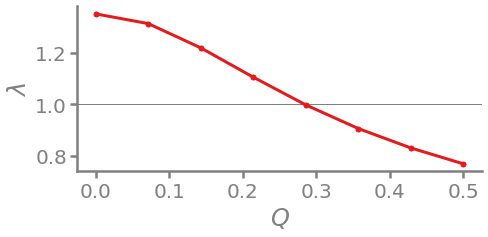

In [12]:
plt.figure(figsize=(3.25*2, 3))

Q_list = np.array([hub.Q[0] for hub in hubbard_Qscan])

plt.axhline(y=1.0, color='black', linewidth=0.5)
plt.plot(Q_list, Es_list, marker='.')

plt.tight_layout()
plt.xlabel(r"$Q$")
plt.ylabel(r"$\lambda$")

plt.show()

From the plot of the leading eigenvalue we extract the critical $Q_c$ at the point where $\lambda = 1$. 
For simplicity, we use linear interpolation to find this point, which then also gives us the coherence length $\xi$.

In [13]:
order = np.argsort(Es_list)
Q_c = np.interp([1.0], Es_list[order], Q_list[order])[0]
print("Critical Q =", Q_c)

xi = 1.0/Q_c
print(r"Coherence length =", xi)

Critical Q = 0.2842635448042766
Coherence length = 3.5178622735058336


## The Superfluid Stiffness and the London penetration depth

While the coherence length $\xi$ could be extracted from the linearized Eliashberg equation, for the London penetration depth $\lambda_L$ we require knowledge of the full gap.
Therefore, we start by evaluating the gap $\Delta$ from non-linearized Eliashberg theory.

Since our interaction is instantaneous and completely local, the anomalous self-energy is momentum and frequency independent, i.e. $\Delta(k,i\omega_n) = \Delta$.
We therefore extract the mean of `delta_wk` as the gap $\Delta$.

In [30]:
from triqs_tprf.eliashberg import solve_eliashberg_nonlinear

delta_list = np.zeros(len(hubbard_Qscan.objects))
for ii,hub in enumerate(hubbard_Qscan):
    # Construct dispersion
    for k in kmesh:
        e_k[k] = dispersion(k.value, hub.t)
        ebar_k[k] = dispersion(k.value - hub.Q, hub.t)

    # Greens functions
    g0_wk = lattice_dyson_g0_wk(mu=hub.mu, e_k=e_k, mesh=wmesh)
    g0bar_wk = lattice_dyson_g0_wk(mu=hub.mu, e_k=ebar_k, mesh=wmesh)

    # Non-linearized Eliashberg
    delta_wk = solve_eliashberg_nonlinear(gamma_pp, g0_wk, gbar_wk=g0bar_wk)
    delta = np.mean(delta_wk.data[:].real)
    assert np.allclose(delta_wk.data[:].real, delta), "Delta is not constant"
    delta_list[ii] = delta

0.376922237712992
0.3759064653536758
0.3718782664517412
0.36042466066072615
0.3177681630166017
1.0409975960964541e-09
5.594402356337123e-10
3.458727846524206e-10


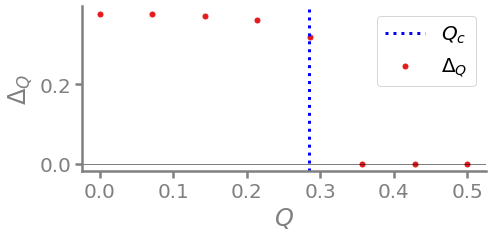

In [15]:
plt.figure(figsize=(3.25*2, 3))

plt.axhline(y=0.0, color='black', linewidth=0.5)
plt.axvline(x=Q_c, color='blue', linestyle=':', label=r"$Q_c$")
plt.scatter(Q_list, delta_list, marker='.', label=r"$\Delta_Q$")

plt.legend()
plt.tight_layout()
plt.xlabel(r"$Q$")
plt.ylabel(r"$\Delta_{Q}$")

plt.show()

Note that the gap is non-zero for $Q < Q_c$ (left of blue dotted line) and vanishes for $Q>Q_c$ (right of blue dotted line), as expected.

The first step to calculating the London penetration depth is evaluating the current density $j_Q$. It is given by

$$
\vec{j}_Q = \frac{2 e}{N_k} \sum_{k} \vec{v}(k) G_Q(k,\tau=0^-) \,,
$$

where $v(k)$ is the electron group velocity and $G$ is the gapped Green's function (note that this is the electron Green's function, not the hole Green's function).
While in the Eliashberg self-consistency equation only the bare Green's function $G^{(0)}$ enters (as a consequence of neglecting normal-state renormalization), we require here the full Green's function $G$ that is dressed by the anomalous self-energy. It can be evaluated using the method `triqs_tprf.lattice.eliashberg_g_wk`.

In [24]:
from triqs.gfs import make_gf_from_fourier
from triqs_tprf.lattice import eliashberg_g_wk

def velocity(k, t):
    return 2.0 * t * np.sin(k[0])

def current_density(v_k, g0_wk, g0bar_wk, delta_wk):
    wmesh, kmesh = g0_wk.mesh.components
    g_sc_wk = eliashberg_g_wk(g0_wk, g0bar_wk, delta_wk)
    
    integrand_w = Gf(mesh=wmesh, target_shape=g_sc_wk.target_shape)
    integrand_w.data[:,0,0] = np.sum(v_k * g_sc_wk.data[:,:,0,0], axis=1) / len(kmesh)
    integrand_t = make_gf_from_fourier(integrand_w)

    j = 2 * integrand_t(0.0)[0,0].real   # Using units where e=1
    return j

In [25]:
j_list = np.zeros(len(hubbard_Qscan.objects))
for ii,hub in enumerate(hubbard_Qscan):
    # Construct dispersion and group velocity
    v_k = np.zeros(len(kmesh))
    for k in kmesh:
        v_k[k.data_index] = velocity(k.value, hub.t)
        e_k[k] = dispersion(k.value, hub.t)
        ebar_k[k] = dispersion(k.value - hub.Q, hub.t)

    # Greens functions
    g0_wk = lattice_dyson_g0_wk(mu=hub.mu, e_k=e_k, mesh=wmesh)
    g0bar_wk = lattice_dyson_g0_wk(mu=hub.mu, e_k=ebar_k, mesh=wmesh)
        
    # Current density
    delta_wk = g0_wk.copy()
    delta_wk.data[:] = delta_list[ii]
    j_list[ii] = current_density(v_k, g0_wk, g0bar_wk, delta_wk)

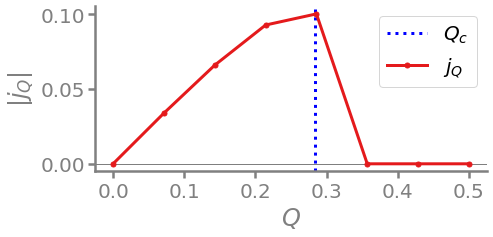

Depairing current = -6.45140313168782e-15


In [27]:
plt.figure(figsize=(3.25*2, 3))

plt.axhline(y=0.0, color='black', linewidth=0.5)
plt.axvline(x=Q_c, color='blue', linestyle=':', label=r"$Q_c$")
plt.plot(Q_list, np.abs(j_list), marker='.', label=r"$j_Q$")

plt.legend()
plt.tight_layout()
plt.xlabel(r"$Q$")
plt.ylabel(r"$|j_{Q}|$")

plt.show()

j_dp = np.max(j_list)
print("Depairing current =", j_dp)

The current density shows a typical dome-like shape as a function of $Q$. At $Q=0$, Cooper pairs have no center-of-mass momentum, such that also the current vanishes.
For $Q>Q_c$ the superconducting order disappears, which also makes a supercurrent impossible.
In between these two limits we find a maximum, which is the depairing current $j_{dp}$. It can be understood as a theoretical upper bound for the critical current, when experimental factors such as sample impurity and device architecture are neglected.

Using linear response theory we can extract the superfluid stiffness $D_S$ from the slope of the current density as

$$
D_S = 2 e \left. \frac{\partial |j_Q|}{\partial Q} \right|_{Q=0} \,,
$$

which also yields the London penetration depth as

$$
\lambda_L = \frac{1}{\sqrt{2 e \mu_0 D_S}} \,,
$$

where $\mu_0$ is the permeability of free space. 
The Ginzburg-Landau factor $\kappa$ is defined as

$$
\kappa = \frac{\lambda_L}{\xi} \,,
$$

from which we can determine whether a superconductor is of type I ($\kappa < 1/\sqrt{2}$) or type II ($\kappa > 1/\sqrt{2}$).
Finally, we can use standard expressions for the critical magnetic fields $\mu_0 H_c$ from Ginzburg-Landau theory and London theory.
For a type I superconductor the critical field is

$$
\mu_0 H_c^I = \frac{\Phi_0}{2\sqrt{2} \pi \lambda_L \xi}
$$

and for a type II superconductor the two critical fields are given by

$$
\mu_0 H_{c1}^{II} = \frac{\Phi_0}{4 \pi \lambda^2_L} \text{ln}\left( \frac{\lambda_L}{\xi} \right) \quad \text{assuming $\kappa \gg 1$}
$$

and

$$
\mu_0 H_{c2}^{II} = \frac{\Phi_0}{2 \pi \xi^2} \,,
$$

where $\Phi_0 = h/2e$ is the magnetic flux quantum.

In [29]:
djdQ = np.gradient(np.abs(j_list), Q_list)

Ds = 2.0 * djdQ[0]

mu0 = 4.0*np.pi
lambda_L = 1.0/np.sqrt(2.0 * mu0 * Ds)

kappa = lambda_L / xi

print("Superfluid stiffness =", Ds)
print("London penetration depth =", lambda_L)
print("Ginzburg-Landau factor =", kappa)

phi0 = np.pi  # We use units where hbar=e=1

if kappa < 1.0/np.sqrt(2):
    print("Type I superconductor")

    Hc = phi0 / (2.0 * np.sqrt(2) * np.pi * lambda_L * xi)
    print("Critical field =", Hc)
else:
    print("Type II superconductor")

    Hc1 = phi0 / (4.0 * np.pi * lambda_L**2) * np.log(kappa)
    Hc2 = phi0 / (2.0 * np.pi * xi**2)

    print("Lower critical field =", Hc1)
    print("Upper critical field =", Hc2)

Superfluid stiffness = 0.9500670601225828
London penetration depth = 0.2046458489045531
Ginzburg-Landau factor = 0.05817335443908866
Type I superconductor
Critical field = 0.4911037317668208


We have shown in this notebook that by adding the finite momentum pairing constraint, we can extract the following additional observables from our microscopic Eliashberg calculations

In [23]:
print("Coherence length =", xi)
print("Depairing current =", j_dp)
print("Superfluid stiffness =", Ds)
print("London penetration depth =", lambda_L)
print("Ginzburg-Landau factor =", kappa)

if kappa < 1.0/np.sqrt(2):
    print("Critical field =", Hc)
else:
    print("Lower critical field =", Hc1)
    print("Upper critical field =", Hc2)

Coherence length = 3.5178622735058336
Depairing current = 0.10036350997579771
Superfluid stiffness = 0.9500670601225828
London penetration depth = 0.2046458489045531
Ginzburg-Landau factor = 0.05817335443908866
Critical field = 0.4911037317668208
